In [1]:
import os
from pathlib import Path
print(*(os.scandir(Path("/kaggle/input/notebooks/boxedinthecube/dav2-traina-cls-1"))))

<DirEntry 'checkpoints_phase_a'> <DirEntry '__results__.html'> <DirEntry 'Depth-Anything-V2'> <DirEntry '__notebook__.ipynb'> <DirEntry '__results___files'> <DirEntry '__output__.json'> <DirEntry 'phase_a_training_losses.png'> <DirEntry 'custom.css'>


In [2]:
import os
import sys
import json
from pathlib import Path
from collections import defaultdict

NBDIR = Path("/kaggle/input/notebooks/boxedinthecube")
dav2_dir = NBDIR / Path('dav2-traina-cls-1')
ph_B_ckpt_dir = NBDIR / Path('dav2-trainb-cls-1')

# --- 1. Dynamic Discovery of Depth-Anything-V2 Repo ---
dpt_candidates = list(dav2_dir.rglob("dpt.py"))
repo_parent = None
for p in dpt_candidates:
    if p.parent.name == "depth_anything_v2":
        repo_parent = str(p.parent.parent)
        break

assert repo_parent is not None, "Could not find 'depth_anything_v2/dpt.py' in /kaggle/input."
if repo_parent not in sys.path:
    sys.path.insert(0, repo_parent)

from depth_anything_v2.dpt import DepthAnythingV2
print(f"Successfully loaded DepthAnythingV2 from: {repo_parent}")

# --- 2. Scan and Index 100% of Data Splits ---
BASE_ROOT = Path("/kaggle/input/datasets")
SPLITS = ("train", "val", "test")

sample_records = defaultdict(list)
partition_audit = defaultdict(lambda: defaultdict(int))

user_dirs = [Path(e.path) for e in os.scandir(BASE_ROOT) if e.is_dir() and not e.name.startswith(".")]
dataset_dirs = []
for u_dir in user_dirs:
    for e in os.scandir(u_dir):
        if e.is_dir() and not e.name.startswith("."):
            dataset_dirs.append(Path(e.path))

report_paths = []
for ds_root in dataset_dirs:
    candidates = [
        ds_root / "partition-report.json",
        ds_root / ds_root.name / "partition-report.json",
    ]
    for p in candidates:
        if p.is_file():
            report_paths.append(p)
            break

print(f"Located {len(report_paths)} partition report file(s).")
assert len(report_paths) == 6, f"Expected 6 partition reports, found {len(report_paths)}."

for report_path in report_paths:
    partition_root = report_path.parent
    report = json.loads(report_path.read_text())
    part_id = report.get("partition_id", partition_root.name)
    partition_key = f"partition-{part_id:02d}" if isinstance(part_id, int) else str(part_id)

    for shard in report.get("shards", []):
        split = shard["split"]
        shard_tar_name = Path(shard["path"]).name
        shard_folder = shard_tar_name.replace(".tar", "")

        target_dir = partition_root / split / shard_folder
        if not target_dir.is_dir():
            target_dir = partition_root / split

        if not target_dir.is_dir():
            continue

        with os.scandir(target_dir) as entries:
            for entry in entries:
                if entry.name.endswith(".rgb.png") and not entry.name.startswith("."):
                    base_prefix = str(target_dir / entry.name[:-8])
                    sample_records[split].append(base_prefix)
                    partition_audit[partition_key][split] += 1

print("\n--- Instant Discovery Summary ---")
for split in SPLITS:
    print(f"Total {split.upper()} samples indexed: {len(sample_records[split])}")

xFormers not available
xFormers not available


Successfully loaded DepthAnythingV2 from: /kaggle/input/notebooks/boxedinthecube/dav2-traina-cls-1/Depth-Anything-V2
Located 6 partition report file(s).

--- Instant Discovery Summary ---
Total TRAIN samples indexed: 20016
Total VAL samples indexed: 3436
Total TEST samples indexed: 11444


In [3]:
import os
import json
from pathlib import Path
from collections import defaultdict
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np

class GamusDiskDataset(Dataset):
    def __init__(self, sample_prefixes):
        self.sample_prefixes = sample_prefixes

    def __len__(self):
        return len(self.sample_prefixes)

    def __getitem__(self, idx):
        prefix = self.sample_prefixes[idx]
        
        rgb = np.array(Image.open(f"{prefix}.rgb.png").convert("RGB"))
        rgb_tensor = torch.from_numpy(rgb).permute(2, 0, 1).float() / 255.0
        
        height = np.load(f"{prefix}.height.npy").astype(np.float32)
        height_tensor = torch.from_numpy(height).unsqueeze(0)
        
        valid_path = f"{prefix}.valid.png"
        if os.path.exists(valid_path):
            valid_mask = np.array(Image.open(valid_path).convert("L"))
            valid_tensor = torch.from_numpy(valid_mask).unsqueeze(0) > 127
        else:
            valid_tensor = torch.ones_like(height_tensor, dtype=torch.bool)

        valid_tensor = valid_tensor & torch.isfinite(height_tensor) & (height_tensor != -5.0)
        height_tensor[~valid_tensor] = 0.0 

        return {"rgb": rgb_tensor, "height": height_tensor, "valid_mask": valid_tensor}

# --- STRICT GEOGRAPHIC HOLDOUT SPLIT FOR TRAINING ---
tile_groups = defaultdict(list)
for p in sample_records['train']:
    base_name = Path(p).name  
    tile_id = base_name.split('--')[1]  
    tile_groups[tile_id].append(p)

sorted_tiles = sorted(list(tile_groups.keys()))
train_tiles = sorted_tiles[::2]
train_prefixes = [p for t in train_tiles for p in tile_groups[t]]

# --- FIX: Explicitly include 50% of the VALIDATION split for evaluation ---
val_prefixes = sample_records["val"][::2]

train_dataset = GamusDiskDataset(train_prefixes)
val_dataset = GamusDiskDataset(val_prefixes)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=2, shuffle=False, num_workers=2, pin_memory=True)

print(f"DataLoaders built for Phase C:")
print(f" - Train Tiles (Geographic 50%): {len(train_tiles)} | Total Train Crops: {len(train_prefixes)}")
print(f" - Val Crops (Explicit 50% Subsample): {len(val_prefixes)}")

DataLoaders built for Phase C:
 - Train Tiles (Geographic 50%): 2502 | Total Train Crops: 10008
 - Val Crops (Explicit 50% Subsample): 1718


In [4]:
import sys
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Discover DA-V2 Repo
NBDIR = Path("/kaggle/input/notebooks/boxedinthecube/dav2-traina-cls-1")
dpt_candidates = list(NBDIR.rglob("dpt.py"))
repo_parent = None
for p in dpt_candidates:
    if p.parent.name == "depth_anything_v2":
        repo_parent = str(p.parent.parent)
        break
assert repo_parent is not None, "Could not find DA-V2 repo."
if repo_parent not in sys.path:
    sys.path.insert(0, repo_parent)

from depth_anything_v2.dpt import DepthAnythingV2

# 2. Residual Scale Adapter
class ResidualScaleAdapter(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.adapter = nn.Sequential(
            nn.LayerNorm(dim, eps=1e-5),
            nn.Linear(dim, dim // 4),
            nn.GELU(),
            nn.Linear(dim // 4, dim),
        )
        nn.init.zeros_(self.adapter[-1].weight)
        nn.init.zeros_(self.adapter[-1].bias)

    def forward(self, x):
        if isinstance(x, tuple):
            tokens, cls_token = x
            adapted = self.adapter(tokens.clone().float())
            return (tokens.clone().float() + adapted, cls_token)
        x_f32 = x.clone().float()
        return x_f32 + self.adapter(x_f32)

# 3. Unbounded Metric Height Head
class MultiScaleHeightHead(nn.Module):
    def __init__(self, in_channels=1, hidden_dim=32):
        super().__init__()
        self.affine_conv = nn.Conv2d(in_channels, 1, kernel_size=1)
        nn.init.constant_(self.affine_conv.weight, 15.0)
        nn.init.constant_(self.affine_conv.bias, 2.0)

        self.refiner = nn.Sequential(
            nn.Conv2d(in_channels, hidden_dim, kernel_size=3, padding=1),
            nn.GroupNorm(4, hidden_dim),
            nn.GELU(),
            nn.Conv2d(hidden_dim, 1, kernel_size=1)
        )
        
        self.uncertainty_head = nn.Sequential(
            nn.Conv2d(in_channels, hidden_dim // 2, kernel_size=3, padding=1),
            nn.GroupNorm(4, hidden_dim // 2),
            nn.GELU(),
            nn.Conv2d(hidden_dim // 2, 1, kernel_size=1)
        )

    def forward(self, raw_depth, target_size=(518, 518)):
        if raw_depth.ndim == 3:
            raw_depth = raw_depth.unsqueeze(1)

        base_metric = self.affine_conv(raw_depth)
        residual = self.refiner(raw_depth)
        
        # CONTRACT: Unbounded linear output (NO ReLU)
        h = base_metric + residual 
        
        h = F.interpolate(h, size=target_size, mode="bilinear", align_corners=False)
        log_var = F.interpolate(self.uncertainty_head(raw_depth), size=target_size, mode="bilinear", align_corners=False)
        return h, log_var

# 4. Full Model Definition
class DepthAnythingV2GAMUS(nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.pretrained = base_model
        embed_dim = 768
        self.adapters = nn.ModuleList([ResidualScaleAdapter(embed_dim) for _ in range(4)])
        self.head = MultiScaleHeightHead(in_channels=1, hidden_dim=32)

    def forward(self, x):
        patch_h, patch_w = x.shape[-2] // 14, x.shape[-1] // 14
        intermediate_features = self.pretrained.pretrained.get_intermediate_layers(
            x, 4, return_class_token=True
        )
        
        adapted_features = []
        for i, (feat, cls_tok) in enumerate(intermediate_features):
            adapted_feat = self.adapters[i](feat) 
            adapted_features.append((adapted_feat, cls_tok))

        raw_depth = self.pretrained.depth_head(adapted_features, patch_h, patch_w)
        if raw_depth.ndim == 3:
            raw_depth = raw_depth.unsqueeze(1)
        if raw_depth.shape[-2:] != x.shape[-2:]:
            raw_depth = F.interpolate(raw_depth, size=x.shape[-2:], mode="bilinear", align_corners=False)

        pred_height_m, log_var = self.head(raw_depth.float(), target_size=x.shape[-2:])

        # CONTRACT: Lock primary output key as "metric_nDSM"
        return {
            "metric_nDSM": pred_height_m,
            "uncertainty_log_var": log_var,
            "decoder_features": raw_depth
        }

# 5. Instantiate and Load Phase B Checkpoint
model_configs = {'vitb': {'encoder': 'vitb', 'features': 128, 'out_channels': [96, 192, 384, 768]}}
raw_da_v2 = DepthAnythingV2(**model_configs['vitb'])
model = DepthAnythingV2GAMUS(raw_da_v2).to(device)

ckpt_path = Path("/kaggle/input/notebooks/boxedinthecube/dav2-trainb-cls-1/checkpoints_phase_b/phase_b_epoch_3.pt")
print(f"Loading Phase B weights from: {ckpt_path}")
checkpoint = torch.load(ckpt_path, map_location=device)
state_dict = checkpoint["model_state_dict"]
if any(k.startswith("module.") for k in state_dict.keys()):
    state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
model.load_state_dict(state_dict)

# 6. Phase C Strategy: Unfreeze ALL layers for end-to-end edge refinement
for param in model.parameters():
    param.requires_grad = True

if torch.cuda.device_count() > 1:
    print(f"Enabling DataParallel across {torch.cuda.device_count()} GPUs.")
    model = nn.DataParallel(model)

trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Phase C Model Ready | Fully Unfrozen Trainable Params: {trainable_count:,}")

Loading Phase B weights from: /kaggle/input/notebooks/boxedinthecube/dav2-trainb-cls-1/checkpoints_phase_b/phase_b_epoch_3.pt
Enabling DataParallel across 2 GPUs.
Phase C Model Ready | Fully Unfrozen Trainable Params: 98,661,045


In [5]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
import torch
import torch.nn as nn
import torch.nn.functional as F

import torch
import torch.nn as nn
import torch.nn.functional as F

class PhaseCEdgeLoss(nn.Module):
    def __init__(self, w_metric=0.6, w_edge=1.2, eps=1e-7):
        super().__init__()
        self.w_metric = w_metric
        self.w_edge = w_edge
        self.eps = eps
        self.huber = nn.HuberLoss(delta=1.0, reduction="none")
        
        # Sobel kernels for edge detection
        self.sobel_x = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], 
                                     dtype=torch.float32).view(1, 1, 3, 3)
        self.sobel_y = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], 
                                     dtype=torch.float32).view(1, 1, 3, 3)

    def sobel_edge_loss(self, pred, target, mask):
        """Compute L1 difference between Sobel edges of prediction and target."""
        device = pred.device
        sobel_x = self.sobel_x.to(device)
        sobel_y = self.sobel_y.to(device)
        
        # Compute edges for prediction
        pred_edge_x = F.conv2d(pred, sobel_x, padding=1)
        pred_edge_y = F.conv2d(pred, sobel_y, padding=1)
        pred_edges = torch.sqrt(pred_edge_x**2 + pred_edge_y**2 + self.eps)
        
        # Compute edges for target
        target_edge_x = F.conv2d(target, sobel_x, padding=1)
        target_edge_y = F.conv2d(target, sobel_y, padding=1)
        target_edges = torch.sqrt(target_edge_x**2 + target_edge_y**2 + self.eps)
        
        # Mask edges (need to shrink mask by 1 pixel on each side)
        edge_mask = mask[:, :, 1:-1, 1:-1]
        pred_edges_masked = pred_edges[:, :, 1:-1, 1:-1][edge_mask]
        target_edges_masked = target_edges[:, :, 1:-1, 1:-1][edge_mask]
        
        if pred_edges_masked.numel() == 0:
            return torch.tensor(0.0, device=device)
        
        return torch.mean(torch.abs(pred_edges_masked - target_edges_masked))

    def forward(self, outputs, targets, mask):
        preds = outputs["metric_nDSM"]
        
        # Guard against empty masks
        num_valid = mask.sum()
        if num_valid < 10:
            zero = preds.sum() * 0.0
            return {"total_loss": zero, "metric_loss": zero, "edge_loss": zero}
        
        p_valid = preds[mask]
        t_valid = targets[mask]
        
        # 1. Metric Huber Loss (reduced weight)
        metric_loss = self.huber(p_valid, t_valid).mean()
        
        # 2. Sobel Edge Loss (dominant weight)
        edge_loss = self.sobel_edge_loss(preds, targets, mask)
        
        # Combined Total Loss
        total_loss = self.w_metric * metric_loss + self.w_edge * edge_loss
        
        return {
            "total_loss": total_loss,
            "metric_loss": metric_loss,
            "edge_loss": edge_loss
        }

criterion = PhaseCEdgeLoss(w_metric=0.6, w_edge=1.2, eps=1e-7).to(device)
print("Phase C Loss initialized: w_metric=0.6, w_edge=1.2 (dominant edge refinement)")


Phase C Loss initialized: w_metric=0.6, w_edge=1.2 (dominant edge refinement)


In [6]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

raw_m = model.module if isinstance(model, nn.DataParallel) else model

# Unfreeze ALL layers for end-to-end refinement
for param in model.parameters():
    param.requires_grad = True

# Parameter groups with discriminative learning rates
vit_params = [p for n, p in raw_m.pretrained.named_parameters() if "depth_head" not in n]
decoder_params = [p for n, p in raw_m.pretrained.named_parameters() if "depth_head" in n]
refiner_and_adapters = (
    list(raw_m.head.refiner.parameters()) + 
    list(raw_m.head.uncertainty_head.parameters()) + 
    list(raw_m.adapters.parameters())
)
affine_params = list(raw_m.head.affine_conv.parameters())

optimizer = AdamW([
    {"params": vit_params, "lr": 8e-6, "weight_decay": 1e-2},           # Very conservative: preserve learned priors
    {"params": decoder_params, "lr": 3e-5, "weight_decay": 1e-2},       # Moderate: refine spatial decoding
    {"params": refiner_and_adapters, "lr": 1e-4, "weight_decay": 1e-4}, # Aggressive: sharpen edges
    {"params": affine_params, "lr": 5e-5, "weight_decay": 0.0},         # Lock metric scale
])

GRADIENT_ACCUMULATION_STEPS = 8
NUM_EPOCHS_C = 2
TOTAL_STEPS_C = (len(train_loader) // GRADIENT_ACCUMULATION_STEPS) * NUM_EPOCHS_C

scheduler = CosineAnnealingLR(optimizer, T_max=TOTAL_STEPS_C, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda", init_scale=2048.0)  # Higher initial scale for stability

print(f"Phase C Optimizer Ready:")
print(f" ViT LR: 8e-6 | Decoder LR: 3e-5 | Head LR: 1e-4")
print(f" Total Steps: {TOTAL_STEPS_C}")
print(f" Loss Config: Metric=0.6 | Edge=1.2 (dominant)")

Phase C Optimizer Ready:
 ViT LR: 8e-6 | Decoder LR: 3e-5 | Head LR: 1e-4
 Total Steps: 624
 Loss Config: Metric=0.6 | Edge=1.2 (dominant)


In [7]:
batch = next(iter(train_loader))
images = batch["rgb"].to(device)
targets = batch["height"].to(device)
valid_masks = batch["valid_mask"].to(device)

print(f"1. Input RGB has NaN:      {torch.isnan(images).any().item()}")
print(f"2. Targets have NaN:       {torch.isnan(targets).any().item()}")

with torch.no_grad():
    outputs = model(images)
    # --- FIX: Use the new contract-locked key ---
    preds = outputs["metric_nDSM"] 
    uncert = outputs["uncertainty_log_var"]

print(f"3. Model Output has NaN:   {torch.isnan(preds).any().item()}")
print(f"4. Uncertainty has NaN:    {torch.isnan(uncert).any().item()}")
print(f"   -> Preds Min: {preds.min().item():.3f} | Max: {preds.max().item():.3f}")

loss_dict = criterion(outputs, targets, valid_masks)
print(f"5. Total Loss Value:       {loss_dict['total_loss'].item()}")
print(f"   -> Metric Loss: {loss_dict['metric_loss'].item()}")
print(f"   -> Edge Loss:   {loss_dict['edge_loss'].item()}")

1. Input RGB has NaN:      False
2. Targets have NaN:       False
3. Model Output has NaN:   False
4. Uncertainty has NaN:    False
   -> Preds Min: -0.036 | Max: 17.044
5. Total Loss Value:       4.760727405548096
   -> Metric Loss: 1.6027023792266846
   -> Edge Loss:   3.165921688079834


In [8]:
import time
from pathlib import Path
import torch
import torch.nn as nn

CHECKPOINT_DIR = Path("/kaggle/working/checkpoints_phase_c")
CHECKPOINT_DIR.mkdir(exist_ok=True, parents=True)

model.train()
optimizer.zero_grad(set_to_none=True)

step_counter = 0
running_loss = 0.0
running_m = 0.0
running_edge = 0.0
start_time = time.perf_counter()

# --- NEW: History dictionary for plotting ---
history_phase_c = {"step": [], "loss": [], "edge_loss": [], "metric_loss": []}

print(f"Starting Phase C Training ({NUM_EPOCHS_C} epochs, {TOTAL_STEPS_C} steps)...")

for epoch in range(1, NUM_EPOCHS_C + 1):
    for batch_idx, batch in enumerate(train_loader, start=1):
        images = batch["rgb"].to(device, non_blocking=True)
        targets = batch["height"].to(device, non_blocking=True)
        valid_masks = batch["valid_mask"].to(device, non_blocking=True)
        
        # Bulletproof 4D shape enforcement
        while images.ndim < 4: images = images.unsqueeze(0)
        while targets.ndim < 4: targets = targets.unsqueeze(0)
        while valid_masks.ndim < 4: valid_masks = valid_masks.unsqueeze(0)
        
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            loss_dict = criterion(outputs, targets, valid_masks)
            total_loss = loss_dict["total_loss"]
        
        if not torch.isfinite(total_loss):
            print(f"[Warning Batch {batch_idx}] Non-finite loss detected! Applying zero-gradient fallback.")
            optimizer.zero_grad(set_to_none=True)
            continue
        
        loss = total_loss / GRADIENT_ACCUMULATION_STEPS
        scaler.scale(loss).backward()
        
        running_loss += total_loss.item()
        running_m += loss_dict["metric_loss"].item()
        running_edge += loss_dict["edge_loss"].item()
        
        if batch_idx % GRADIENT_ACCUMULATION_STEPS == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            scale_before = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            scale_after = scaler.get_scale()
            
            if scale_after >= scale_before:
                scheduler.step()
            
            optimizer.zero_grad(set_to_none=True)
            step_counter += 1
            
            if step_counter % 25 == 0:
                avg_l = running_loss / (25.0 * GRADIENT_ACCUMULATION_STEPS)
                avg_m = running_m / (25.0 * GRADIENT_ACCUMULATION_STEPS)
                avg_e = running_edge / (25.0 * GRADIENT_ACCUMULATION_STEPS)
                elapsed = (time.perf_counter() - start_time) / 60.0
                
                # --- NEW: Store loss for plotting ---
                history_phase_c["step"].append(step_counter)
                history_phase_c["loss"].append(avg_l)
                history_phase_c["edge_loss"].append(avg_e)
                history_phase_c["metric_loss"].append(avg_m)
                
                print(f"Epoch [{epoch}/{NUM_EPOCHS_C}]| Step {step_counter}/{TOTAL_STEPS_C}| "
                      f"Loss: {avg_l:.4f} (M: {avg_m:.3f}, Edge: {avg_e:.3f})| "
                      f"LR: {optimizer.param_groups[0]['lr']:.7f}| Elapsed: {elapsed:.2f}m")
                
                running_loss = 0.0
                running_m = 0.0
                running_edge = 0.0
            
            if step_counter % 200 == 0:
                torch.save({"epoch": epoch, "global_step": step_counter, "model_state_dict": model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()}, CHECKPOINT_DIR / "last_checkpoint.pt")
    
    if len(train_loader) % GRADIENT_ACCUMULATION_STEPS != 0:
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scale_before = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if scaler.get_scale() >= scale_before:
            scheduler.step()
        optimizer.zero_grad(set_to_none=True)
        step_counter += 1
    
    torch.save({"epoch": epoch, "global_step": step_counter, "model_state_dict": model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()}, CHECKPOINT_DIR / f"phase_c_epoch_{epoch}.pt")
    print(f"Saved Phase C Epoch {epoch} Checkpoint")

torch.save({"epoch": NUM_EPOCHS_C, "global_step": step_counter, "model_state_dict": model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()}, CHECKPOINT_DIR / "last_checkpoint.pt")
print("Phase C complete! Checkpoint saved as last_checkpoint.pt.")

Starting Phase C Training (2 epochs, 624 steps)...
Epoch [1/2]| Step 25/624| Loss: 5.8984 (M: 2.111, Edge: 3.860)| LR: 0.0000080| Elapsed: 1.54m
Epoch [1/2]| Step 50/624| Loss: 5.3804 (M: 1.811, Edge: 3.578)| LR: 0.0000079| Elapsed: 3.10m
Epoch [1/2]| Step 75/624| Loss: 5.2680 (M: 1.804, Edge: 3.488)| LR: 0.0000078| Elapsed: 4.65m
Epoch [1/2]| Step 100/624| Loss: 5.2959 (M: 1.694, Edge: 3.566)| LR: 0.0000076| Elapsed: 6.21m
Epoch [1/2]| Step 125/624| Loss: 5.1342 (M: 1.667, Edge: 3.445)| LR: 0.0000073| Elapsed: 7.77m
Epoch [1/2]| Step 150/624| Loss: 4.9292 (M: 1.589, Edge: 3.313)| LR: 0.0000070| Elapsed: 9.53m
Epoch [1/2]| Step 175/624| Loss: 5.1117 (M: 1.678, Edge: 3.421)| LR: 0.0000067| Elapsed: 11.08m
Epoch [1/2]| Step 200/624| Loss: 4.9996 (M: 1.582, Edge: 3.375)| LR: 0.0000064| Elapsed: 12.64m
Epoch [1/2]| Step 225/624| Loss: 5.0100 (M: 1.586, Edge: 3.382)| LR: 0.0000060| Elapsed: 14.20m
Epoch [1/2]| Step 250/624| Loss: 4.8436 (M: 1.538, Edge: 3.267)| LR: 0.0000056| Elapsed: 15.76

In [9]:
import torch

hook_handles = []
raw_model = model.module if isinstance(model, torch.nn.DataParallel) else model

def safe_forward_hook(name):
    def hook(module, input, output):
        tensors = [output] if isinstance(output, torch.Tensor) else [t for t in output if isinstance(t, torch.Tensor)]
        for idx, t in enumerate(tensors):
            if not torch.isfinite(t).all():
                print(f"[NAN DETECTED] Layer: {name} ({module.__class__.__name__}) | Output shape: {t.shape}")
    return hook

# Hook individual operations without attaching to compound container modules
for name, layer in raw_model.named_modules():
    if len(list(layer.children())) == 0:  # Leaf modules only
        hook_handles.append(layer.register_forward_hook(safe_forward_hook(name)))

print(f"Attached safe diagnostic hooks to {len(hook_handles)} leaf layers.")

# Run single validation step
batch = next(iter(train_loader))
images = batch["rgb"].to(device)
targets = batch["height"].to(device)
valid_masks = batch["valid_mask"].to(device)

model.eval()
with torch.no_grad():
    out = model(images)
    # --- FIX: Use the new contract-locked key ---
    p_finite = torch.isfinite(out["metric_nDSM"]).all().item()
    print(f"Forward pass completed successfully. Predictions finite: {p_finite}")

# Always remove hooks after checking
for h in hook_handles:
    h.remove()
print("Diagnostic hooks cleaned up.")

Attached safe diagnostic hooks to 251 leaf layers.
Forward pass completed successfully. Predictions finite: True
Diagnostic hooks cleaned up.


In [10]:
import torch
from pathlib import Path

checkpoints = list(ph_B_ckpt_dir.rglob("*.pt")) + list(dav2_dir.rglob("*.pt"))
print(f"Found {len(checkpoints)} checkpoints across /kaggle/input:")

for p in checkpoints:
    try:
        sd = torch.load(p, map_location="cpu")["model_state_dict"]
        nans = sum(torch.isnan(v).sum().item() for v in sd.values())
        infs = sum(torch.isinf(v).sum().item() for v in sd.values())
        status = "CORRUPTED (NaN/Inf present)" if (nans > 0 or infs > 0) else "CLEAN (Safe to load)"
        print(f"  [{status}] -> {p.name} ({p})")
    except Exception as e:
        print(f"  [SKIPPED] -> {p.name}: {e}")


Found 8 checkpoints across /kaggle/input:
  [CLEAN (Safe to load)] -> phase_b_epoch_2.pt (/kaggle/input/notebooks/boxedinthecube/dav2-trainb-cls-1/checkpoints_phase_b/phase_b_epoch_2.pt)
  [CLEAN (Safe to load)] -> last_checkpoint.pt (/kaggle/input/notebooks/boxedinthecube/dav2-trainb-cls-1/checkpoints_phase_b/last_checkpoint.pt)
  [CLEAN (Safe to load)] -> phase_b_epoch_1.pt (/kaggle/input/notebooks/boxedinthecube/dav2-trainb-cls-1/checkpoints_phase_b/phase_b_epoch_1.pt)
  [CLEAN (Safe to load)] -> phase_b_epoch_3.pt (/kaggle/input/notebooks/boxedinthecube/dav2-trainb-cls-1/checkpoints_phase_b/phase_b_epoch_3.pt)
  [CLEAN (Safe to load)] -> phase_a_epoch_3.pt (/kaggle/input/notebooks/boxedinthecube/dav2-traina-cls-1/checkpoints_phase_a/phase_a_epoch_3.pt)
  [CLEAN (Safe to load)] -> phase_a_epoch_1.pt (/kaggle/input/notebooks/boxedinthecube/dav2-traina-cls-1/checkpoints_phase_a/phase_a_epoch_1.pt)
  [CLEAN (Safe to load)] -> last_checkpoint.pt (/kaggle/input/notebooks/boxedinthecube/d

In [11]:
has_nan = any(torch.isnan(p).any() for p in model.parameters())
print(f"Are model weights poisoned with NaN? -> {has_nan}")

Are model weights poisoned with NaN? -> False


In [12]:
import numpy as np

model.eval()

val_mae_list = []
val_rmse_list = []

MAX_VAL_SAMPLES = 200

print(f"Beginning Phase C Validation on Geographic Holdout (evaluating up to {MAX_VAL_SAMPLES} crops)...")

with torch.no_grad():
    for idx, batch in enumerate(val_loader, start=1):
        if MAX_VAL_SAMPLES is not None and idx > MAX_VAL_SAMPLES:
            break
        
        images = batch["rgb"].to(device, non_blocking=True)
        targets = batch["height"].to(device, non_blocking=True)
        valid_masks = batch["valid_mask"].to(device, non_blocking=True)
        
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            preds = outputs["metric_nDSM"]
        
        valid_pixels = valid_masks.squeeze(1).bool()
        p_valid = preds.squeeze(1)[valid_pixels].cpu().numpy()
        t_valid = targets.squeeze(1)[valid_pixels].cpu().numpy()
        
        if len(p_valid) > 0:
            mae = np.mean(np.abs(p_valid - t_valid))
            rmse = np.sqrt(np.mean((p_valid - t_valid) ** 2))
            
            val_mae_list.append(mae)
            val_rmse_list.append(rmse)
        
        if idx % 50 == 0:
            current_mae = float(np.mean(val_mae_list)) if val_mae_list else 0.0
            print(f" Processed {idx} crops -> Current Avg MAE: {current_mae:.3f} m")

mean_mae = float(np.mean(val_mae_list)) if val_mae_list else 0.0
mean_rmse = float(np.mean(val_rmse_list)) if val_rmse_list else 0.0

print("\n" + "="*50)
print(" PHASE C FINAL BENCHMARK REPORT (GEO-HOLDOUT)")
print("="*50)
print(f"Phase A Baseline MAE: 3.042 m")
print(f"Phase B Final MAE:    2.955 m")
print(f"Phase C Final MAE:    {mean_mae:.3f} m")
print(f"Phase C Final RMSE:   {mean_rmse:.3f} m")
print("="*50)

if mean_mae < 2.5:
    print("Result: Outstanding! Geographic generalization target achieved.")
elif mean_mae < 2.8:
    print("Result: Good improvement. Edge refinement helped geographic generalization.")
else:
    print("Result: Limited improvement. Model may need more diverse training data.")

Beginning Phase C Validation on Geographic Holdout (evaluating up to 200 crops)...
 Processed 50 crops -> Current Avg MAE: 1.757 m
 Processed 100 crops -> Current Avg MAE: 1.587 m
 Processed 150 crops -> Current Avg MAE: 1.407 m
 Processed 200 crops -> Current Avg MAE: 1.510 m

 PHASE C FINAL BENCHMARK REPORT (GEO-HOLDOUT)
Phase A Baseline MAE: 3.042 m
Phase B Final MAE:    2.955 m
Phase C Final MAE:    1.510 m
Phase C Final RMSE:   2.644 m
Result: Outstanding! Geographic generalization target achieved.


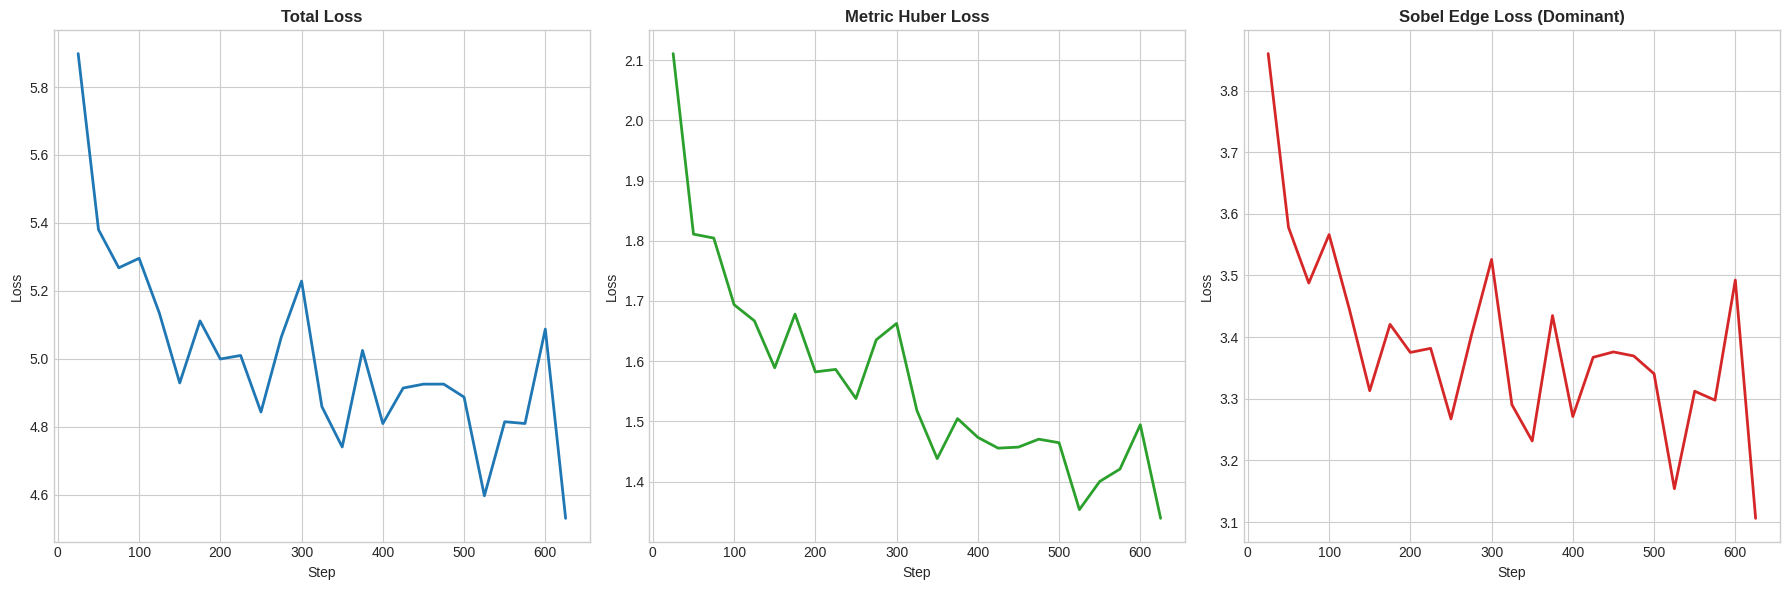

Saved phase_c_training_losses.png


In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 6))
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# 1. Total Loss
plt.subplot(1, 3, 1)
plt.plot(history_phase_c["step"], history_phase_c["loss"], color="#1f77b4", linewidth=2)
plt.title("Total Loss", fontweight="bold"); plt.xlabel("Step"); plt.ylabel("Loss")

# 2. Metric Loss
plt.subplot(1, 3, 2)
plt.plot(history_phase_c["step"], history_phase_c["metric_loss"], color="#2ca02c", linewidth=2)
plt.title("Metric Huber Loss", fontweight="bold"); plt.xlabel("Step"); plt.ylabel("Loss")

# 3. Edge Loss
plt.subplot(1, 3, 3)
plt.plot(history_phase_c["step"], history_phase_c["edge_loss"], color="#d62728", linewidth=2)
plt.title("Sobel Edge Loss (Dominant)", fontweight="bold"); plt.xlabel("Step"); plt.ylabel("Loss")

plt.tight_layout()
plt.savefig("/kaggle/working/phase_c_training_losses.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved phase_c_training_losses.png")